# Analysis of Results Common
Comparing individual `_best.csv` files against concatenated batch results, followed by TMT Validation.

In [1]:
import pandas as pd
import glob
import os
import numpy as np
import ast
from scipy.stats import pearsonr, zscore
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Ensure pandas is avail


In [2]:


RESULTS_DIR = "../results_val"


## 1. Load Individual `*_best.csv` Files

In [3]:

# Find all protein_best.csv files
best_files = glob.glob(os.path.join(RESULTS_DIR, "*_best.csv"))
print(f"Found {len(best_files)} individual best files.")

dfs = []
for f in best_files:
    try:
        df = pd.read_csv(f)
        dfs.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs:
    df_best_all = pd.concat(dfs, ignore_index=True)
    # Sort for consistency
    df_best_all.sort_values("protein", inplace=True)
    df_best_all.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Best Shape: {df_best_all.shape}")
    display(df_best_all.head())
else:
    df_best_all = pd.DataFrame()
    print("No best files loaded.")


Found 1809 individual best files.
Concatenated Best Shape: (1809, 10)


,protein,best_sample,best_abs_error,mse_all_others,params_dict,feat_coeffs_dict,zscore_genes,zscore_mu,zscore_sigma,zscore_eps
0,A2M,UMUC3_URINARY_TRACT,0.003011,0.836941,"{'alpha': 1.0, 'l1_ratio': 0.1}","{'A1BG': 0.0, 'A2M': 0.05601153568687824, 'AAD...","['A1BG', 'A2M', 'AADAT', 'AASS', 'ABCB6', 'ABI...","[2.821546846143207, 0.8868445119261132, 2.2698...","[2.051967442561821, 1.8051704733585499, 1.2569...",1.000000e-08
1,AARS2,SQ1_LUNG,0.000137,0.140420,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'A2M': 0.0, 'AARS2': 0.15406732440684603, 'AA...","['A2M', 'AARS2', 'AATK', 'ABCC10', 'ABCG1', 'A...","[0.8871246572874287, 3.4942220091470135, 1.098...","[1.8050580488255072, 0.6163178413829652, 1.117...",1.000000e-08
2,AASDHPPT,HEC59_ENDOMETRIUM,0.000364,0.273664,"{'alpha': 0.1, 'l1_ratio': 0.9}","{'A4GALT': -0.0, 'AAAS': 0.0, 'AARS2': 0.0, 'A...","['A4GALT', 'AAAS', 'AARS2', 'AASDHPPT', 'ABCB1...","[2.103931763318877, 5.69152738256317, 3.493995...","[1.5504930921286346, 0.5083307393271205, 0.616...",1.000000e-08
3,ABCB7,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.000245,0.147214,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AASS': -0.0, 'ABCB6': -0.0, 'ABCB7': 0.22758...","['AASS', 'ABCB6', 'ABCB7', 'ABI3', 'ABL1', 'AC...","[2.029682970399025, 4.270079436520009, 4.11333...","[1.4572810773960054, 1.3446260392182268, 0.563...",1.000000e-08
4,ABCD3,CAL33_UPPER_AERODIGESTIVE_TRACT,0.000973,0.202043,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AAAS': -0.0, 'AASDHPPT': -0.0118042086846440...","['AAAS', 'AASDHPPT', 'ABCC3', 'ABCC6', 'ABCD3'...","[5.692029499779636, 4.809574950496353, 3.54140...","[0.5086774092766796, 0.610410849672823, 2.4961...",1.000000e-08


## 2. Load Batch Result Files

In [4]:

# Find batch files (assuming pattern results_batch_*.csv)
batch_files = glob.glob(os.path.join(RESULTS_DIR, "*batch*.csv"))
print(f"Found {len(batch_files)} batch files.")

dfs_batch = []
for f in batch_files:
    try:
        df = pd.read_csv(f)
        dfs_batch.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs_batch:
    df_batch_concat = pd.concat(dfs_batch, ignore_index=True)
    df_batch_concat.sort_values("protein", inplace=True)
    df_batch_concat.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Batch Shape: {df_batch_concat.shape}")
    display(df_batch_concat.head())
else:
    df_batch_concat = pd.DataFrame()
    print("No batch files loaded.")


Found 0 batch files.
No batch files loaded.


## 3. Compare

In [5]:

# Check if they are the same
if not df_best_all.empty and not df_batch_concat.empty:
    # 1. Compare protein lists
    prots_best = set(df_best_all['protein'].unique())
    prots_batch = set(df_batch_concat['protein'].unique())
    
    missing_in_batch = prots_best - prots_batch
    missing_in_best = prots_batch - prots_best
    
    print(f"Proteins in Best: {len(prots_best)}")
    print(f"Proteins in Batch: {len(prots_batch)}")
    
    if missing_in_batch:
        print(f"Proteins in Best but NOT in Batch: {len(missing_in_batch)}")
    if missing_in_best:
        print(f"Proteins in Batch but NOT in Best: {len(missing_in_best)}")
        
    # Check shape equality
    if df_best_all.shape == df_batch_concat.shape:
         try:
            pd.testing.assert_frame_equal(df_best_all, df_batch_concat, check_like=True)
            print("SUCCESS: DataFrames are identical (pd.testing.assert_frame_equal passed).")
         except AssertionError as e:
            print(f"DataFrames are NOT identical: {e}")
    else:
        print("Shapes differ, cannot be identical.")

else:
    print("Cannot compare - one or both dataframes are empty.")


Cannot compare - one or both dataframes are empty.


## 4. TMT Data Loading (Pre-Processed with Gene Symbols)

In [6]:


# --- UPDATED: Load from Validation Folder ---
RNA_PATH = "../val_data/TMT_transcriptomics.joblib"
PROT_PATH = "../val_data/TMT_proteomics.joblib"

print(f"Loading Validation TMT Data from: {RNA_PATH} and {PROT_PATH}")

rna_df = None
prot_df = None

if os.path.exists(RNA_PATH) and os.path.exists(PROT_PATH):
    try:
        rna_df = joblib.load(RNA_PATH)
        prot_df = joblib.load(PROT_PATH)
        
        # Ensure we have pandas DataFrames
        if not isinstance(rna_df, pd.DataFrame):
            print("Warning: Loaded RNA object is not a DataFrame.")
        if not isinstance(prot_df, pd.DataFrame):
            print("Warning: Loaded Protein object is not a DataFrame.")

        print(f"TMT RNA Shape: {rna_df.shape}")
        print(f"TMT Protein Shape: {prot_df.shape}")
        
        # Display heads if possible (requires IPython display which is avail in notebook)
        try:
            display(rna_df.head())
            display(prot_df.head())
        except:
            print(rna_df.head())
            print(prot_df.head())
        
    except Exception as e:
        print(f"Error loading joblib files: {e}")
else:
    print(f"Validation files not found. Current CWD: {os.getcwd()}")
    if not os.path.exists("../validation"):
        print("Folder ../validation does not exist.")


Loading Validation TMT Data from: ../val_data/TMT_transcriptomics.joblib and ../val_data/TMT_proteomics.joblib
TMT RNA Shape: (1924, 11822)
TMT Protein Shape: (1924, 2156)


,A1BG,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMP,AARS2,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_2021_1,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_2,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_3,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_4,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_5,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261


,A2M,AARS2,AASDHPPT,ABCB7,ABCD3,ABCE1,ABCF1,ABHD10,ABHD11,ABHD12,...,YWHAH,YWHAQ,YWHAZ,ZC3H15,ZC3HAV1,ZFR,ZMPSTE24,ZNF207,ZW10,ZYX
BRAIN_2021_1,-0.502200,-1.303529,-1.759635,-0.602404,-1.685510,-2.038622,-1.642326,-0.480090,-1.303494,-2.046275,...,-1.825659,-0.718545,-1.594815,-2.038661,-3.395116,-2.217040,-1.584718,-2.030506,-2.738972,-2.094629
BRAIN_2021_2,-0.204137,-2.674597,-2.286908,-1.358367,-0.472175,-1.923911,-1.960258,-2.658298,-1.150290,-2.457124,...,-2.823357,-2.591220,-1.941476,-1.448028,-1.142884,-2.099895,-1.666139,-2.654453,-3.009835,-1.039994
BRAIN_2021_3,0.041017,-2.345995,-1.777309,-0.904556,-1.866794,-2.224800,-1.910088,-2.094739,-0.566066,-2.210322,...,-1.920919,-3.021612,-1.602053,-2.192381,-3.838561,-3.243517,-2.313361,-3.210174,-3.243079,-1.194251
BRAIN_2021_4,-0.889541,-1.624300,-1.310905,0.790857,-0.754318,-1.691173,-2.815819,-0.202525,0.246079,-1.811747,...,-2.853412,-2.477688,-1.312220,-2.467856,-2.899840,-3.602331,-0.768234,-2.968897,-1.316719,-2.030824
BRAIN_2021_5,-2.062631,-1.358497,-1.979379,-0.283117,-1.217947,-1.826304,-1.884007,-0.584780,-1.610849,-1.249494,...,-2.636891,-2.837671,-1.993881,-1.833922,-2.907152,-1.311497,-1.163917,-2.105762,-2.439429,-0.121891


## 5. Check Features & Normalize

In [7]:

if rna_df is not None:
    # 1. SKIP Normalization (Data already normalized) - Just handle NaNs
    print("Skipping z-score normalization (data already normalized). Filling NaNs with 0...")
    
    # Just fill NaNs (crucial to prevent NaNs in prediction)
    rna_z = rna_df.fillna(0)
    
    print("NaNs filled with 0.")
    display(rna_z.head())
    
    # Check coverage
    if not df_best_all.empty:
        import ast
        example_coeffs = ast.literal_eval(df_best_all.iloc[0]['feat_coeffs_dict'])
        needed = list(example_coeffs.keys())
        present = [g for g in needed if g in rna_z.columns]
        print(f"Example Model ({df_best_all.iloc[0]['protein']}) feature coverage: {len(present)}/{len(needed)}")


Skipping z-score normalization (data already normalized). Filling NaNs with 0...
NaNs filled with 0.


,A1BG,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMP,AARS2,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_2021_1,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_2,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_3,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_4,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261
BRAIN_2021_5,0.545975,5.296317,0.508969,1.295025,1.520018,0.863317,1.285711,0.820239,1.402171,1.242133,...,0.856721,1.627889,2.145133,4.044142,1.907477,0.9384,0.500179,1.023829,0.859434,0.91261


Example Model (A2M) feature coverage: 1193/1194


In [8]:

# 5.5 Setting up Analysis
print("\n=======================================================")
print(" PART 1: Analysis with ALL Tissues (No Filtering) ")
print("=======================================================\n")

# Note: Filtering will be done in Part 2 below.



 PART 1: Analysis with ALL Tissues (No Filtering) 



In [9]:

# --- CHECK PERCENTAGE OF ZEROS PER TISSUE ---
if 'rna_z' in locals() and not rna_z.empty:
    print("\n--- Percentage of Zeros per Tissue (RNA Data) ---")
    
    # Helper to get tissue from index (if not already defined)
    def get_tissue_check(idx):
        parts = idx.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return idx
    
    rna_zeros = rna_z.copy()
    rna_zeros['Tissue'] = [get_tissue_check(x) for x in rna_zeros.index]
    
    # Calculate % zeros: (Count of 0s / Total Cells) * 100
    zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)
    
    display(zero_stats.sort_values(ascending=False).to_frame(name="% Zeros"))
else:
    print("rna_z not found. Cannot check zeros.")
# --------------------------------------------



--- Percentage of Zeros per Tissue (RNA Data) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_34436\1257190750.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)


,% Zeros
Tissue,
BRAIN_2021,0.0
BREAST2020,0.0
COLON_2019,0.0
ENDOMET_VAL,0.0
HEADNECK_2021,0.0
LIVER_VAL,0.0
LUNG2021,0.0
LUNG_2020_SMOKE,0.0
LUNG_VAL,0.0


## 6. Predict TMT Proteins & Evaluate

In [10]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total TMT RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total TMT RNA Features: 11822
Protein A2M: Needed 1194, Present 1193, Missing 1
  -> First 3 missing: ['ZIM2']
Protein AARS2: Needed 1194, Present 1189, Missing 5
  -> First 3 missing: ['C1QTNF7', 'ZFP2', 'FOLR2']
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1185, Missing 9
  -> First 3 missing: ['ICOS', 'TLR8', 'HK3']
Protein ABCD3: Needed 1194, Present 1192, Missing 2
  -> First 3 missing: ['FOLR2', 'SLC9B1']


In [11]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 186 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,AASDHPPT,7.127774,0.366017,0.365646,True
1,ABHD11,12.250897,-0.317651,-0.317266,True
2,ACIN1,15.196684,-0.493425,-0.492326,True
3,ACSF2,5.678494,0.087953,0.087728,True
4,ACSL1,5.293602,0.330888,0.330419,True


Average MSE: 10.981506179764706
Average Correlation: 0.16616249216741688
Average Cosine Similarity: 0.1643276566112533

Error Table (Predicted - Actual):


,BRAIN_2021_1,BRAIN_2021_2,BRAIN_2021_3,BRAIN_2021_4,BRAIN_2021_5,BRAIN_2021_6,BRAIN_2021_7,BRAIN_2021_8,BRAIN_2021_9,BRAIN_2021_10,...,RENAL_2019_176,RENAL_2019_177,RENAL_2019_178,RENAL_2019_179,RENAL_2019_180,RENAL_2019_181,RENAL_2019_182,RENAL_2019_183,RENAL_2019_184,RENAL_2019_185
AASDHPPT,1.971321,2.498594,1.988996,1.522592,2.191066,2.324887,1.026369,2.881154,2.169016,2.596573,...,-4.492242,-4.448289,-4.454684,-4.324917,-4.457889,-4.440083,-4.493401,-4.399533,-4.478243,-4.422502
ABHD11,-0.934839,-1.088043,-1.672267,-2.484412,-0.627484,-0.930696,-1.368594,-1.023242,-0.805354,-0.959704,...,-2.938569,-3.008943,-4.633093,-7.187208,-3.189185,-3.245833,-5.144876,-3.252101,-4.257938,-3.425365
ACIN1,1.303285,1.676820,1.934030,1.476177,1.270308,1.005700,0.709465,1.787314,0.393616,1.157973,...,-6.559126,-6.697777,-6.468728,-6.536409,-6.506047,-6.798636,-6.511846,-6.658316,-6.490440,-6.688632
ACSF2,0.607702,1.575627,1.933103,-0.020909,0.597995,1.465928,1.852663,1.364301,0.785522,1.251194,...,-3.878056,-3.741714,-3.864796,-3.867862,-3.836492,-5.293985,-3.867194,-3.771775,-3.879566,-5.813660
ACSL1,1.900827,2.675162,1.355117,1.715439,1.931314,1.702463,2.384557,0.718042,2.225471,1.298272,...,-3.949625,-3.417335,-3.813807,-3.572690,-3.912017,-3.342409,-3.891096,-3.389833,-4.014516,-3.685152


In [12]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
167,TMX3,5.875288,0.547558,0.546410
98,MACF1,8.224738,0.546965,0.546056
32,COL12A1,3.260516,0.506794,0.487720
64,FAM3C,6.468806,0.495929,0.493023
23,CD47,4.821827,0.483169,0.483117
115,PDXDC1,6.927980,0.479345,0.478206
7,AGR2,7.384555,0.475922,0.449038
122,PPA2,8.986701,0.466499,0.462430
119,PLOD1,4.469124,0.462373,0.455458
109,NID1,3.561096,0.462062,0.425601



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
184,VIM,2.320750,0.441382,0.423610
24,CDH1,2.340024,0.178350,0.151488
10,AKAP12,2.518430,0.412228,0.412224
138,RBM47,2.590282,0.289392,0.287858
99,MAP1B,2.627725,0.329038,0.328292
52,DPYSL3,2.807041,0.370045,0.366021
126,PRPH,2.860106,0.329799,0.311671
22,CAV1,2.870352,0.370735,0.367395
13,ANXA6,2.936767,0.303075,0.300450
112,NRP1,2.937707,0.322528,0.320235



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
167,TMX3,5.875288,0.547558,0.546410
98,MACF1,8.224738,0.546965,0.546056
64,FAM3C,6.468806,0.495929,0.493023
32,COL12A1,3.260516,0.506794,0.487720
23,CD47,4.821827,0.483169,0.483117
115,PDXDC1,6.927980,0.479345,0.478206
122,PPA2,8.986701,0.466499,0.462430
14,AP1M1,10.601978,0.460338,0.459574
174,TUBB6,4.640933,0.457793,0.457691
119,PLOD1,4.469124,0.462373,0.455458



Total NaNs in Error Table: 0


In [13]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
PEDBRAIN_2020       5.273119
LUNG_2020_SMOKE     5.948392
BREAST2020          5.989734
BRAIN_2021          6.056497
COLON_2019          6.172545
ENDOMET_VAL         6.187387
LUNG2021            8.744347
PANCREA2021        25.868818
HEADNECK_2021      26.624462
RENAL_2019         26.677165
Name: MSE, dtype: float64

In [14]:

# =======================================================
# PART 2: Analysis with FILTERED Tissues
# =======================================================

excluded_tissues = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']

if 'rna_z' in locals() and 'prot_df' in locals():
    def get_tissue_filter(sample_name):
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name

    print(f"Original Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Identify samples to remove
    samples_to_remove = []
    for s in rna_z.index:
        t = get_tissue_filter(s)
        if t in excluded_tissues:
            samples_to_remove.append(s)

    print(f"Removing {len(samples_to_remove)} samples from excluded tissues: {excluded_tissues}")

    # Filter in-place (or overwrite variable)
    # We overwrite rna_z and prot_df so the duplicated cells works as is
    rna_z = rna_z.drop(index=samples_to_remove, errors='ignore')
    prot_df = prot_df.drop(index=samples_to_remove, errors='ignore')

    print(f"Filtered Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Print remaining tissues
    remaining_tissues = sorted(list(set([get_tissue_filter(s) for s in rna_z.index])))
    print(f"\nRemaining Tissues ({len(remaining_tissues)}): {remaining_tissues}")
else:
    print("Dataframes rna_z or prot_df not found.")


Original Samples: RNA=1924, Prot=1924
Removing 476 samples from excluded tissues: ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
Filtered Samples: RNA=1448, Prot=1448

Remaining Tissues (9): ['BRAIN_2021', 'BREAST2020', 'COLON_2019', 'ENDOMET_VAL', 'LIVER_VAL', 'LUNG2021', 'LUNG_2020_SMOKE', 'LUNG_VAL', 'PEDBRAIN_2020']


## 6. Predict TMT Proteins & Evaluate

In [15]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total TMT RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total TMT RNA Features: 11822
Protein A2M: Needed 1194, Present 1193, Missing 1
  -> First 3 missing: ['ZIM2']
Protein AARS2: Needed 1194, Present 1189, Missing 5
  -> First 3 missing: ['C1QTNF7', 'ZFP2', 'FOLR2']
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1185, Missing 9
  -> First 3 missing: ['ICOS', 'TLR8', 'HK3']
Protein ABCD3: Needed 1194, Present 1192, Missing 2
  -> First 3 missing: ['FOLR2', 'SLC9B1']


In [16]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 186 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,AASDHPPT,2.862346,0.033789,0.224357,True
1,ABHD11,6.058787,0.109728,-0.079124,True
2,ACIN1,5.616848,-0.054037,-0.219221,True
3,ACSF2,2.547806,0.129292,0.162584,True
4,ACSL1,2.810914,0.130297,0.167992,True


Average MSE: 5.905534621576926
Average Correlation: 0.04789525691279867
Average Cosine Similarity: 0.1097663669565101

Error Table (Predicted - Actual):


,BRAIN_2021_1,BRAIN_2021_2,BRAIN_2021_3,BRAIN_2021_4,BRAIN_2021_5,BRAIN_2021_6,BRAIN_2021_7,BRAIN_2021_8,BRAIN_2021_9,BRAIN_2021_10,...,PEDBRAIN_2020_179,PEDBRAIN_2020_180,PEDBRAIN_2020_181,PEDBRAIN_2020_182,PEDBRAIN_2020_183,PEDBRAIN_2020_184,PEDBRAIN_2020_185,PEDBRAIN_2020_186,PEDBRAIN_2020_187,PEDBRAIN_2020_188
AASDHPPT,1.971321,2.498594,1.988996,1.522592,2.191066,2.324887,1.026369,2.881154,2.169016,2.596573,...,2.293148,1.262242,1.831035,1.933656,1.724951,1.657156,1.982097,1.639790,2.130501,2.226920
ABHD11,-0.934839,-1.088043,-1.672267,-2.484412,-0.627484,-0.930696,-1.368594,-1.023242,-0.805354,-0.959704,...,1.601061,2.213742,2.327422,1.756535,2.976981,2.033293,3.310821,2.722108,3.668873,3.687258
ACIN1,1.303285,1.676820,1.934030,1.476177,1.270308,1.005700,0.709465,1.787314,0.393616,1.157973,...,2.055359,3.809391,3.415485,3.670323,3.579522,3.355741,4.190664,2.616741,3.203464,3.964833
ACSF2,0.607702,1.575627,1.933103,-0.020909,0.597995,1.465928,1.852663,1.364301,0.785522,1.251194,...,0.923231,0.915609,-0.393699,0.167832,1.257236,1.089813,0.768432,-0.120314,1.464662,0.444272
ACSL1,1.900827,2.675162,1.355117,1.715439,1.931314,1.702463,2.384557,0.718042,2.225471,1.298272,...,-0.161426,0.945860,0.645536,0.566937,0.985866,1.314589,1.584387,0.626183,1.047384,1.463801


In [17]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
64,FAM3C,3.023397,0.420291,0.381151
134,RALGAPB,5.618256,0.330995,0.170107
23,CD47,2.977383,0.328883,0.377794
68,FHL1,1.951149,0.310914,0.356983
119,PLOD1,2.630769,0.302787,0.243206
56,EEF1A2,7.394180,0.281962,0.299727
122,PPA2,3.714101,0.280274,0.238702
130,PSMD1,6.333788,0.255261,0.362969
20,CAMK2G,4.004227,0.254485,0.202248
160,STXBP2,2.234240,0.253552,0.450755



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
184,VIM,1.010595,-0.041661,0.386537
138,RBM47,1.197333,-0.003713,0.203659
126,PRPH,1.315189,-0.098032,0.319246
63,F11R,1.474615,0.219151,0.271769
13,ANXA6,1.629451,0.074484,0.258971
22,CAV1,1.665577,0.243463,0.374511
24,CDH1,1.740281,-0.025815,-0.383948
58,EHHADH,1.808526,0.099059,0.426698
68,FHL1,1.951149,0.310914,0.356983
99,MAP1B,2.035774,0.004983,0.102473



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
160,STXBP2,2.234240,0.253552,0.450755
58,EHHADH,1.808526,0.099059,0.426698
111,NPLOC4,6.410009,0.202652,0.424723
184,VIM,1.010595,-0.041661,0.386537
54,DTYMK,5.854327,0.112848,0.385233
167,TMX3,2.407978,0.140625,0.381512
64,FAM3C,3.023397,0.420291,0.381151
23,CD47,2.977383,0.328883,0.377794
22,CAV1,1.665577,0.243463,0.374511
130,PSMD1,6.333788,0.255261,0.362969



Total NaNs in Error Table: 0


In [18]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
LUNG_VAL           4.429452
LIVER_VAL          5.178295
PEDBRAIN_2020      5.273119
LUNG_2020_SMOKE    5.948392
BREAST2020         5.989734
BRAIN_2021         6.056497
COLON_2019         6.172545
ENDOMET_VAL        6.187387
LUNG2021           8.744347
Name: MSE, dtype: float64


--- Global Performance Metrics ---



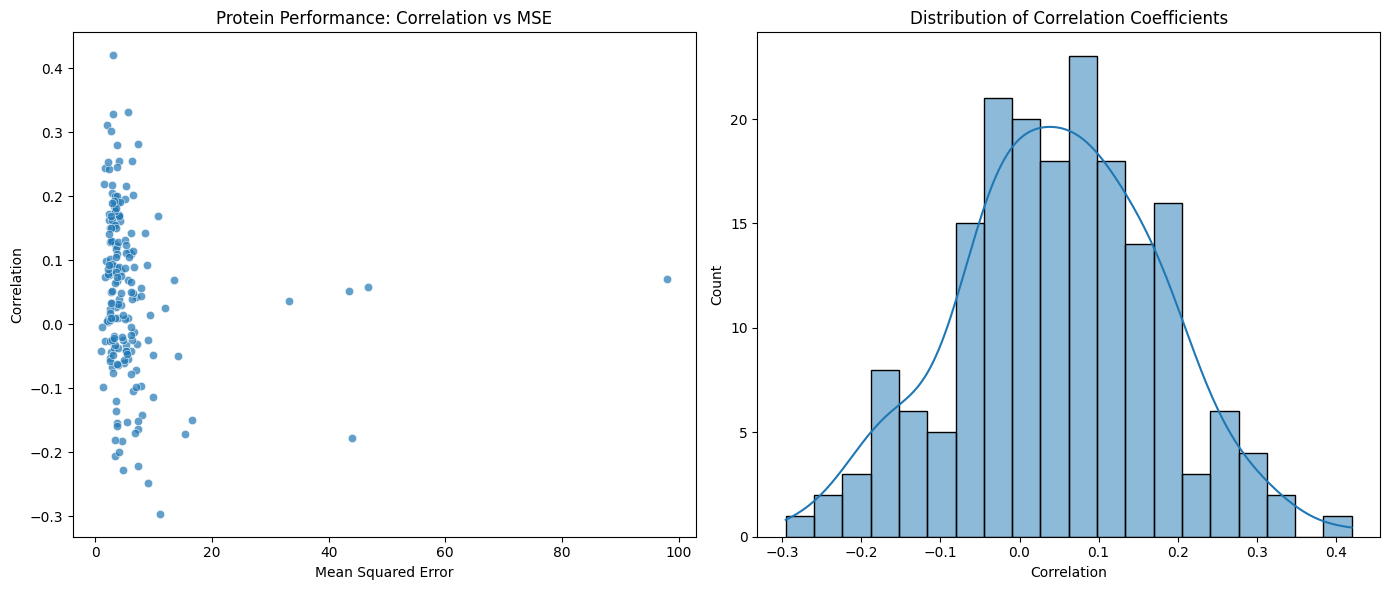

In [19]:

# 10. Global Visualizations

if 'results_df' in locals() and not results_df.empty:
    print("\n--- Global Performance Metrics ---\n")
    
    plt.figure(figsize=(14, 6))
    
    # 1. Correlation vs MSE Scatter
    plt.subplot(1, 2, 1)
    sns.scatterplot(data=results_df, x='MSE', y='Correlation', alpha=0.7)
    plt.title('Protein Performance: Correlation vs MSE')
    plt.xlabel('Mean Squared Error')
    plt.ylabel('Correlation')
    
    # 2. Correlation Distribution
    plt.subplot(1, 2, 2)
    sns.histplot(results_df['Correlation'], bins=20, kde=True)
    plt.title('Distribution of Correlation Coefficients')
    plt.xlabel('Correlation')
    
    plt.tight_layout()
    plt.show()



--- Tissue Performance Comparison ---



C:\Users\hp\AppData\Local\Temp\ipykernel_34436\3732386305.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)


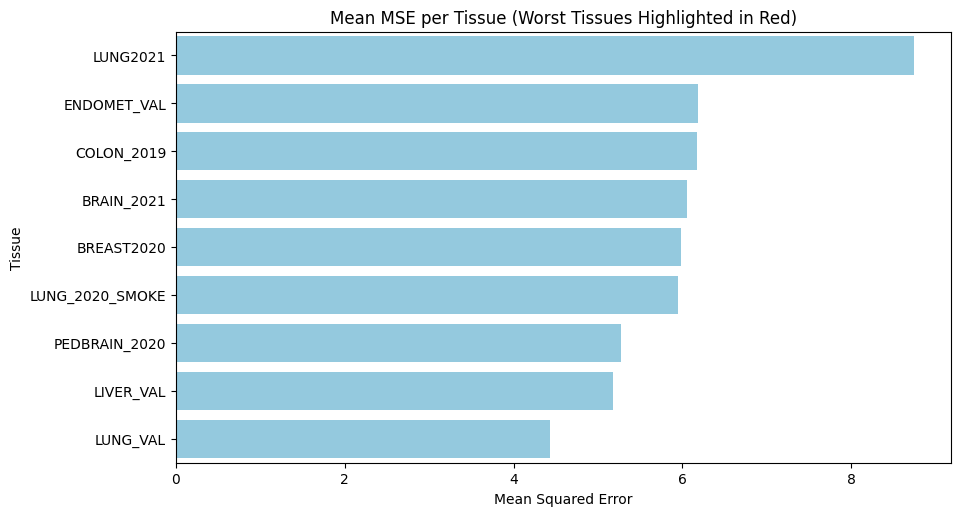

In [20]:

# 11. Tissue Performance Visualization
if 'tissue_df' in locals() and not tissue_df.empty:
    print("\n--- Tissue Performance Comparison ---\n")
    
    # Calculate mean MSE per tissue
    tissue_means = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=False)
    
    plt.figure(figsize=(10, len(tissue_means) * 0.4 + 2))
    
    # Highlight worst tissues
    worst_targets = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
    colors = ['red' if t in worst_targets else 'skyblue' for t in tissue_means.index]
    
    sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)
    plt.title("Mean MSE per Tissue (Worst Tissues Highlighted in Red)")
    plt.xlabel("Mean Squared Error")
    plt.show()
